In [16]:
# Import and load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns',None)
sns.set_style('whitegrid')

df = pd.read_csv('/content/Telco-Customer-Churn.csv')
print("Shape:", df.shape)
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
# Cell 2 — Structure, types, and missing values
df.info()
print("\n--- Missing values per column ---")
print(df.isnull().sum())
print("\n--- Target balance ---")
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


/tmp/ipykernel_2482/1036980548.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1,1],


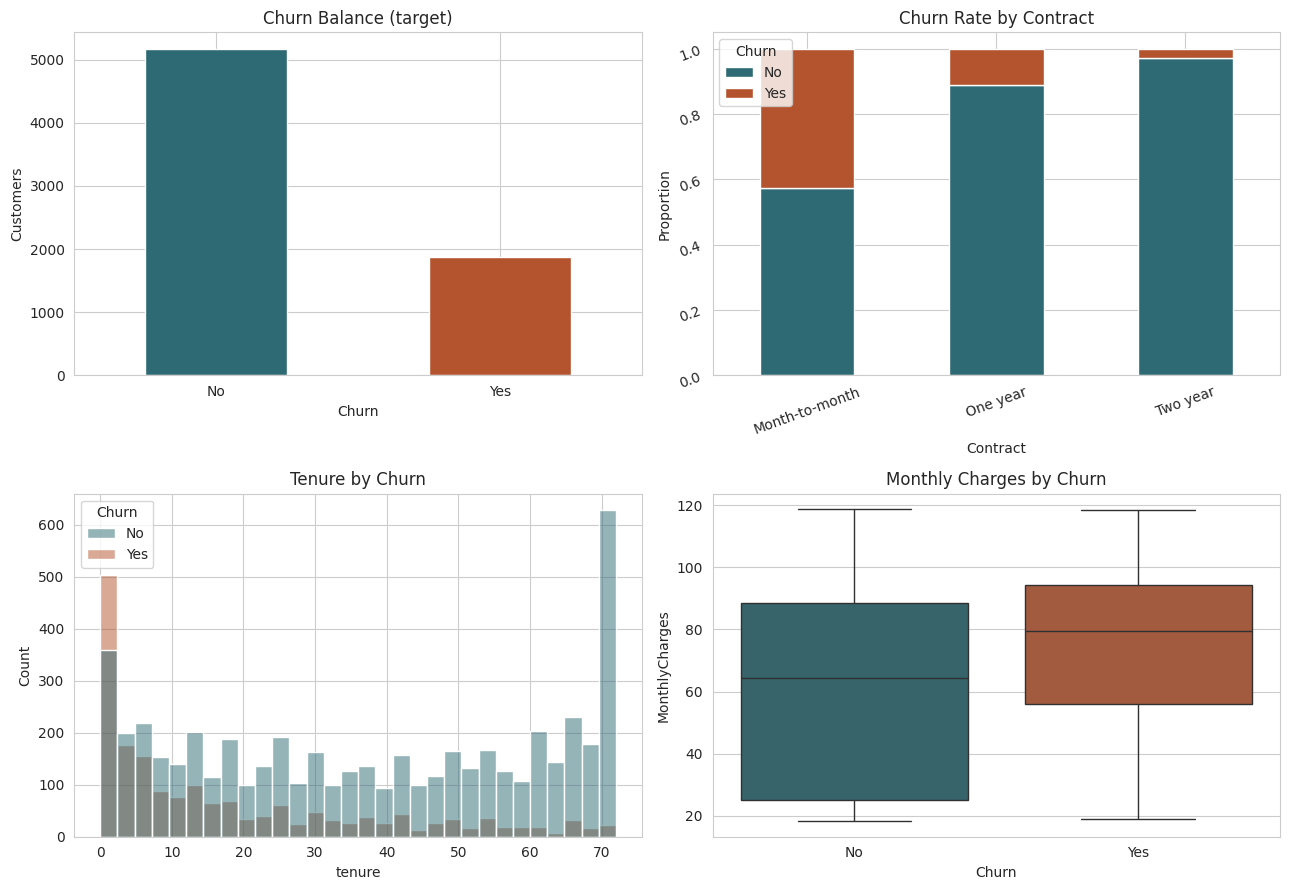

In [19]:
# Visual EDA
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Overall churn balance
df['Churn'].value_counts().plot(kind='bar', ax=axes[0,0], color=['#2d6a73','#b4542f'])
axes[0,0].set_title('Churn Balance (target)')
axes[0,0].set_ylabel('Customers'); axes[0,0].tick_params(rotation=0)

# 2. Churn by contract type
pd.crosstab(df['Contract'], df['Churn'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[0,1], color=['#2d6a73','#b4542f'])
axes[0,1].set_title('Churn Rate by Contract'); axes[0,1].tick_params(rotation=20)
axes[0,1].set_ylabel('Proportion')

# 3. Tenure distribution by churn
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, ax=axes[1,0],
             palette=['#2d6a73','#b4542f'])
axes[1,0].set_title('Tenure by Churn')

# 4. Monthly charges by churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1,1],
            palette=['#2d6a73','#b4542f'])
axes[1,1].set_title('Monthly Charges by Churn')

plt.tight_layout()
plt.show()

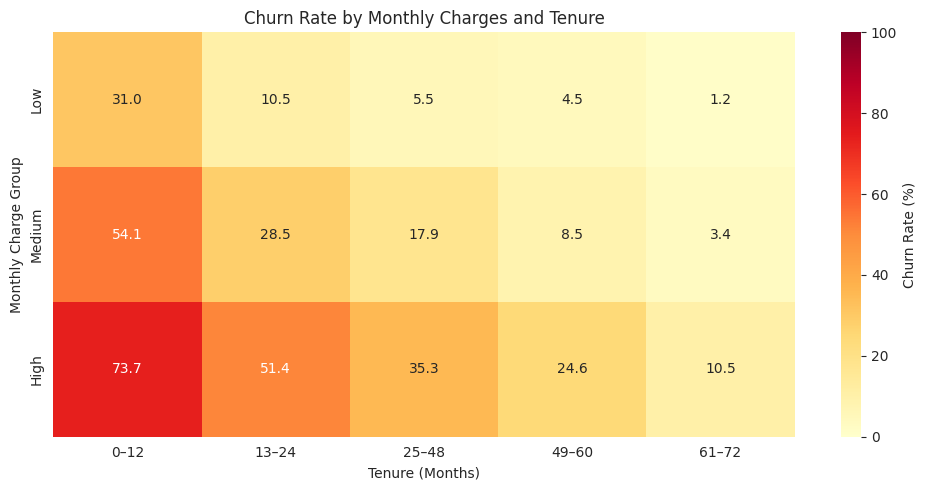

In [22]:

df_plot = df.copy()

df_plot['TenureGroup'] = pd.cut(
    df_plot['tenure'],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=['0–12', '13–24', '25–48', '49–60', '61–72']
)

df_plot['ChargeGroup'] = pd.qcut(
    df_plot['MonthlyCharges'],
    q=3,
    labels=['Low', 'Medium', 'High'],
    duplicates='drop'
)

churn_rate = df_plot.pivot_table(
    index='ChargeGroup',
    columns='TenureGroup',
    values='Churn',
    aggfunc=lambda x: (x == 'Yes').mean(),
    observed=False
) * 100

plt.figure(figsize=(10, 5))
sns.heatmap(
    churn_rate,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title('Churn Rate by Monthly Charges and Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charge Group')
plt.tight_layout()
plt.show()

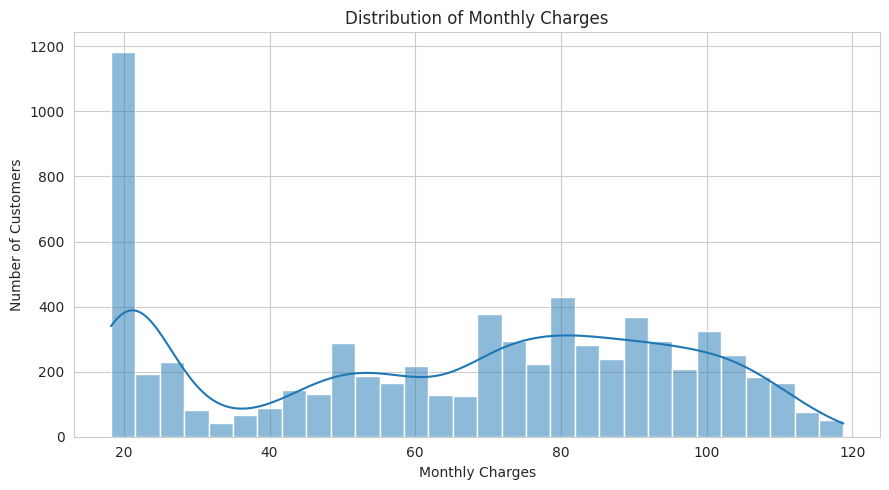

In [23]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='MonthlyCharges', bins=30, kde=True)

plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [25]:
#Data preparation

# 1. Fix TotalCharges: it's text, with 11 blanks for brand-new customers
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Blanks found in TotalCharges:", df['TotalCharges'].isnull().sum())

# Those 11 are tenure=0 customers, so total billed is 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 2. Drop the ID column (useless for prediction)
df = df.drop('customerID', axis=1)

# 3. Encode target: Yes=1 (churned), No=0 (stayed)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 4. One-hot encode all remaining categorical columns
df_encoded = pd.get_dummies(df, drop_first=True)

print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Blanks found in TotalCharges: 11
Shape after encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False


In [26]:
# Train/test split
from sklearn.model_selection import train_test_split

# features (X) = everthing except the target (y) = Chrun.
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # hold out 20% for testing
    random_state=42,     # makes the split reproducible
    stratify=y           # keep the same churn ratio in both sets
)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)
print("\nChurn rate in train:", round(y_train.mean(), 3))
print("Churn rate in test: ", round(y_test.mean(), 3))

Training set: (5634, 30)
Test set:     (1409, 30)

Churn rate in train: 0.265
Churn rate in test:  0.265


In [27]:
# Balance the training set with SMOTE
from imblearn.over_sampling import SMOTE

print("Before SMOTE:", y_train.value_counts().to_dict())

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("After SMOTE: ", y_train_bal.value_counts().to_dict())
print("\nTraining shape after SMOTE:", X_train_bal.shape)

Before SMOTE: {0: 4139, 1: 1495}
After SMOTE:  {0: 4139, 1: 4139}

Training shape after SMOTE: (8278, 30)


In [31]:
# Model 1: Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_bal, y_train_bal)

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_proba)
print("Random Forest ROC-AUC:", round(rf_auc, 4))

Random Forest ROC-AUC: 0.8212


In [32]:
# Model 2: XGBoost
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=5,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train_bal, y_train_bal)

xgb_pred = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]

xgb_auc = roc_auc_score(y_test, xgb_proba)
print("XGBoost ROC-AUC:", round(xgb_auc, 4))

XGBoost ROC-AUC: 0.8185


RANDOM FOREST
              precision    recall  f1-score   support

      Stayed       0.85      0.84      0.85      1035
     Churned       0.58      0.60      0.59       374

    accuracy                           0.78      1409
   macro avg       0.71      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

XGBOOST
              precision    recall  f1-score   support

      Stayed       0.85      0.83      0.84      1035
     Churned       0.56      0.60      0.58       374

    accuracy                           0.77      1409
   macro avg       0.70      0.71      0.71      1409
weighted avg       0.77      0.77      0.77      1409



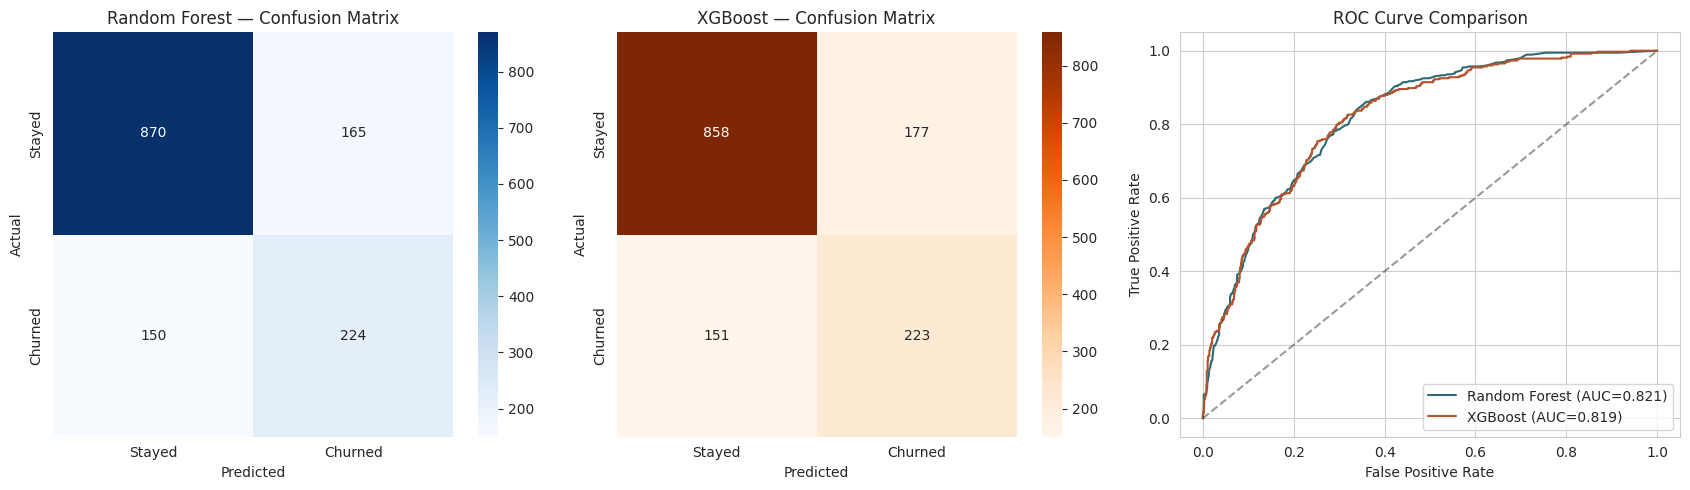

In [33]:
#  Full evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

print("="*55)
print("RANDOM FOREST")
print("="*55)
print(classification_report(y_test, rf_pred, target_names=['Stayed','Churned']))

print("="*55)
print("XGBOOST")
print("="*55)
print(classification_report(y_test, xgb_pred, target_names=['Stayed','Churned']))

# Confusion matrices + ROC curves
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d',
            cmap='Blues', ax=axes[0],
            xticklabels=['Stayed','Churned'], yticklabels=['Stayed','Churned'])
axes[0].set_title('Random Forest — Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt='d',
            cmap='Oranges', ax=axes[1],
            xticklabels=['Stayed','Churned'], yticklabels=['Stayed','Churned'])
axes[1].set_title('XGBoost — Confusion Matrix')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')

# ROC curves
for name, proba, color in [('Random Forest', rf_proba, '#2d6a73'),
                           ('XGBoost', xgb_proba, '#b4542f')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[2].plot(fpr, tpr, color=color, label=f'{name} (AUC={auc:.3f})')
axes[2].plot([0,1],[0,1],'k--',alpha=0.4)
axes[2].set_title('ROC Curve Comparison')
axes[2].set_xlabel('False Positive Rate'); axes[2].set_ylabel('True Positive Rate')
axes[2].legend()

plt.tight_layout()
plt.show()

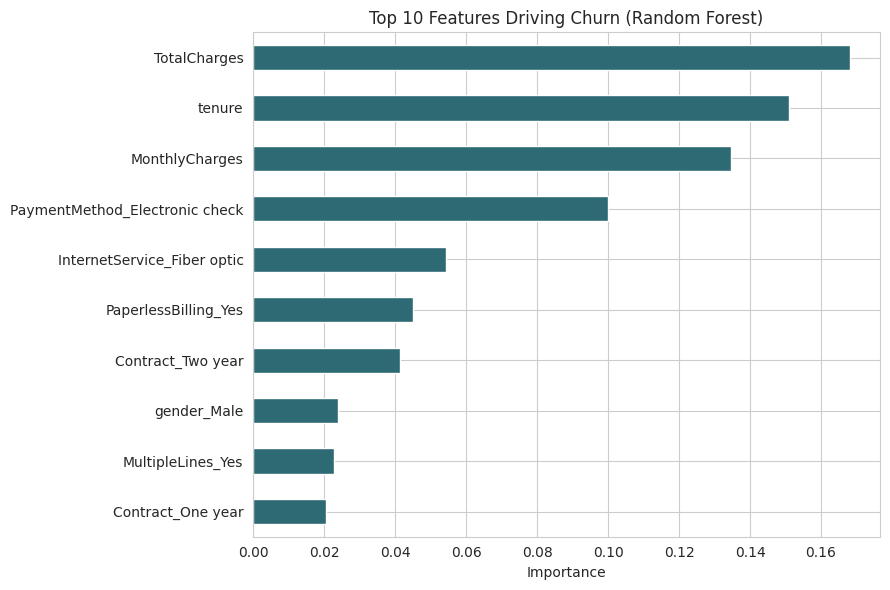

Top 10 features:
TotalCharges                      0.1682
tenure                            0.1510
MonthlyCharges                    0.1346
PaymentMethod_Electronic check    0.1000
InternetService_Fiber optic       0.0544
PaperlessBilling_Yes              0.0449
Contract_Two year                 0.0414
gender_Male                       0.0239
MultipleLines_Yes                 0.0226
Contract_One year                 0.0206
dtype: float64


In [34]:
# Feature importance (top 10)
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 6))
top10.sort_values().plot(kind='barh', color='#2d6a73')
plt.title('Top 10 Features Driving Churn (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print("Top 10 features:")
print(top10.round(4))

In [36]:
# lean model using only the top 10 features
top10_features = top10.index.tolist()
print("Using features:", top10_features)

# Subset train (balanced) and test to just those columns
X_train_lean = X_train_bal[top10_features]
X_test_lean  = X_test[top10_features]

rf_lean = RandomForestClassifier(
    n_estimators=200, random_state=42, n_jobs=-1
)
rf_lean.fit(X_train_lean, y_train_bal)

lean_proba = rf_lean.predict_proba(X_test_lean)[:, 1]
lean_auc = roc_auc_score(y_test, lean_proba)

print("\n--- Comparison ---")
print(f"Full model  (30 features): ROC-AUC = {rf_auc:.4f}")
print(f"Lean model  (10 features): ROC-AUC = {lean_auc:.4f}")
print(f"Difference: {rf_auc - lean_auc:+.4f}")

Using features: ['TotalCharges', 'tenure', 'MonthlyCharges', 'PaymentMethod_Electronic check', 'InternetService_Fiber optic', 'PaperlessBilling_Yes', 'Contract_Two year', 'gender_Male', 'MultipleLines_Yes', 'Contract_One year']

--- Comparison ---
Full model  (30 features): ROC-AUC = 0.8212
Lean model  (10 features): ROC-AUC = 0.7989
Difference: +0.0223


Top  5 features -> ROC-AUC = 0.7819
Top 10 features -> ROC-AUC = 0.7989
Top 15 features -> ROC-AUC = 0.8153
Top 20 features -> ROC-AUC = 0.8158
Top 25 features -> ROC-AUC = 0.8184
Top 30 features -> ROC-AUC = 0.8180


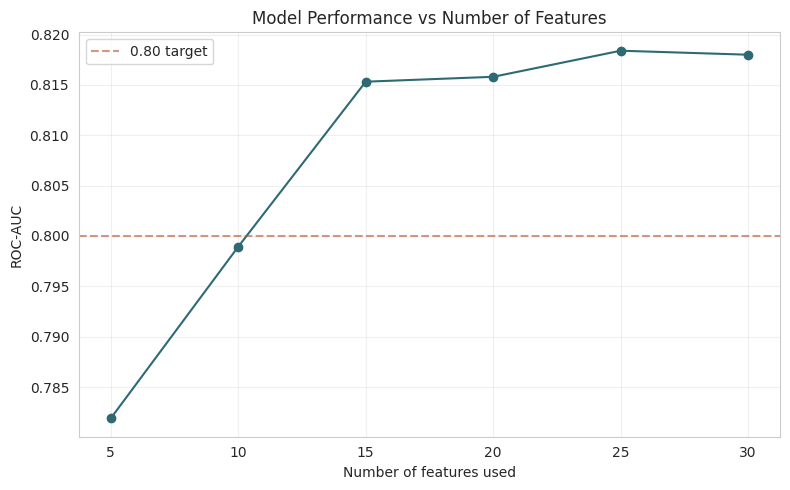

In [37]:
#How many features do we really need?
ranked = importances.sort_values(ascending=False).index.tolist()

results = []
for n in [5, 10, 15, 20, 25, 30]:
    feats = ranked[:n]
    m = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    m.fit(X_train_bal[feats], y_train_bal)
    proba = m.predict_proba(X_test[feats])[:, 1]
    auc = roc_auc_score(y_test, proba)
    results.append((n, auc))
    print(f"Top {n:2d} features -> ROC-AUC = {auc:.4f}")

# Plot the curve
ns  = [r[0] for r in results]
auc = [r[1] for r in results]
plt.figure(figsize=(8,5))
plt.plot(ns, auc, 'o-', color='#2d6a73')
plt.axhline(0.80, color='#b4542f', ls='--', alpha=0.6, label='0.80 target')
plt.title('Model Performance vs Number of Features')
plt.xlabel('Number of features used')
plt.ylabel('ROC-AUC')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Save ALL figures for the README (full process)
import os
os.makedirs('images', exist_ok=True)

# Reload raw data so EDA charts keep original Yes/No labels
raw = pd.read_csv('Telco-Customer-Churn.csv')

# ---------- 1. EDA overview (2x2) ----------
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
raw['Churn'].value_counts().plot(kind='bar', ax=ax[0,0], color=['#2d6a73','#b4542f'])
ax[0,0].set_title('Churn Balance (target)'); ax[0,0].tick_params(rotation=0); ax[0,0].set_ylabel('Customers')
pd.crosstab(raw['Contract'], raw['Churn'], normalize='index').plot(
    kind='bar', stacked=True, ax=ax[0,1], color=['#2d6a73','#b4542f'])
ax[0,1].set_title('Churn Rate by Contract'); ax[0,1].tick_params(rotation=20); ax[0,1].set_ylabel('Proportion')
sns.histplot(data=raw, x='tenure', hue='Churn', bins=30, ax=ax[1,0], palette=['#2d6a73','#b4542f'])
ax[1,0].set_title('Tenure by Churn')
sns.boxplot(data=raw, x='Churn', y='MonthlyCharges', ax=ax[1,1], palette=['#2d6a73','#b4542f'])
ax[1,1].set_title('Monthly Charges by Churn')
plt.tight_layout(); plt.savefig('images/01_eda_overview.png', dpi=120, bbox_inches='tight'); plt.close()

# ---------- 2. Churn-rate heatmap (tenure x charges) ----------
dp = raw.copy()
dp['TenureGroup'] = pd.cut(dp['tenure'], bins=[-1,12,24,48,60,72],
                           labels=['0-12','13-24','25-48','49-60','61-72'])
dp['ChargeGroup'] = pd.qcut(dp['MonthlyCharges'], q=3, labels=['Low','Medium','High'], duplicates='drop')
cr = dp.pivot_table(index='ChargeGroup', columns='TenureGroup', values='Churn',
                    aggfunc=lambda x:(x=='Yes').mean(), observed=False)*100
plt.figure(figsize=(10,5))
sns.heatmap(cr, annot=True, fmt='.1f', cmap='YlOrRd', vmin=0, vmax=100,
            cbar_kws={'label':'Churn Rate (%)'})
plt.title('Churn Rate by Monthly Charges and Tenure')
plt.xlabel('Tenure (Months)'); plt.ylabel('Monthly Charge Group')
plt.tight_layout(); plt.savefig('images/02_churn_heatmap.png', dpi=120, bbox_inches='tight'); plt.close()

# ---------- 3. Confusion matrices ----------
fig, ax = plt.subplots(1, 2, figsize=(12,5))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Stayed','Churned'], yticklabels=['Stayed','Churned'])
ax[0].set_title('Random Forest'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt='d', cmap='Oranges', ax=ax[1],
            xticklabels=['Stayed','Churned'], yticklabels=['Stayed','Churned'])
ax[1].set_title('XGBoost'); ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Actual')
plt.tight_layout(); plt.savefig('images/03_confusion_matrices.png', dpi=120, bbox_inches='tight'); plt.close()

# ---------- 4. ROC curve comparison ----------
plt.figure(figsize=(7,6))
for name, proba, color in [('Random Forest', rf_proba, '#2d6a73'), ('XGBoost', xgb_proba, '#b4542f')]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, color=color, label=f'{name} (AUC={roc_auc_score(y_test,proba):.3f})')
plt.plot([0,1],[0,1],'k--',alpha=0.4)
plt.title('ROC Curve Comparison'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend()
plt.tight_layout(); plt.savefig('images/04_roc_curve.png', dpi=120, bbox_inches='tight'); plt.close()

# ---------- 5. Feature importance ----------
plt.figure(figsize=(9,6))
top10.sort_values().plot(kind='barh', color='#2d6a73')
plt.title('Top 10 Features Driving Churn'); plt.xlabel('Importance')
plt.tight_layout(); plt.savefig('images/05_feature_importance.png', dpi=120, bbox_inches='tight'); plt.close()

# ---------- 6. Feature-count experiment ----------
plt.figure(figsize=(8,5))
plt.plot([r[0] for r in results], [r[1] for r in results], 'o-', color='#2d6a73')
plt.axhline(0.80, color='#b4542f', ls='--', alpha=0.6, label='0.80 target')
plt.title('Model Performance vs Number of Features')
plt.xlabel('Number of features'); plt.ylabel('ROC-AUC'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('images/06_feature_count.png', dpi=120, bbox_inches='tight'); plt.close()

print("Saved:", sorted(os.listdir('images')))

/tmp/ipykernel_2482/3793092009.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=raw, x='Churn', y='MonthlyCharges', ax=ax[1,1], palette=['#2d6a73','#b4542f'])


Saved: ['01_eda_overview.png', '02_churn_heatmap.png', '03_confusion_matrices.png', '04_roc_curve.png', '05_feature_importance.png', '06_feature_count.png', 'feature_count.png', 'feature_importance.png', 'roc_curve.png']


In [40]:
# Zip the images and download
import shutil
from google.colab import files

shutil.make_archive('churn_images', 'zip', 'images')
files.download('churn_images.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>